# **Explainable AI for Thyroid Nodule Detection Using Ultrasound Images**

## **Project Overview**

This project focuses on developing a deep learning-based image classification system to classify thyroid ultrasound images into two categories using a custom Convolutional Neural Network (CNN) architecture called **FibonacciNet**.

The model learns visual patterns and features from ultrasound images to distinguish between the two image classes. The dataset is explored, prepared, split into training, validation, and testing sets, and used to train the model.

To improve the interpretability of the model's predictions, **Grad-CAM (Gradient-weighted Class Activation Mapping)** is used to generate visual heatmaps highlighting image regions that contribute to the model's prediction.

The project combines deep learning-based image classification and explainable AI techniques to explore how AI can support the analysis of thyroid ultrasound images.

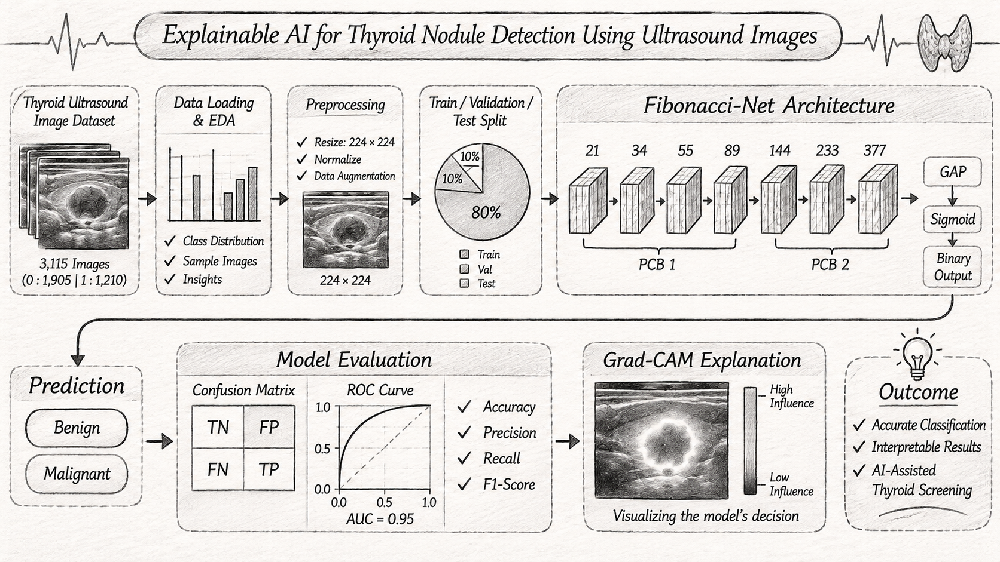

## **Fibonacci-Net Architecture**

Fibonacci-Net is a custom Convolutional Neural Network (CNN) architecture that uses a Fibonacci-inspired filter configuration for feature extraction. The Fibonacci sequence is a mathematical sequence in which each number is obtained by adding the two preceding numbers. Inspired by this sequence, the network uses progressively increasing filter counts of 21, 34, 55, 89, 144, 233, and 377 to extract image features at different levels of complexity.

The architecture incorporates convolutional blocks with Batch Normalization, ReLU activation, and Max Pooling, along with parallel feature connections (PCB) that reuse intermediate features from earlier layers. A custom Avg2MaxPooling layer combines average and maximum pooling operations, while Depthwise Separable Convolution is used in the deeper layers for feature processing. Global Average Pooling is applied to summarize the extracted features, followed by a sigmoid activation function for binary classification.

In this project, the custom Fibonacci-Net architecture is used to classify thyroid ultrasound images into two classes. Grad-CAM is additionally employed to visualize the regions of the input image that contribute to the model's prediction, providing a visual interpretation of the classification process.


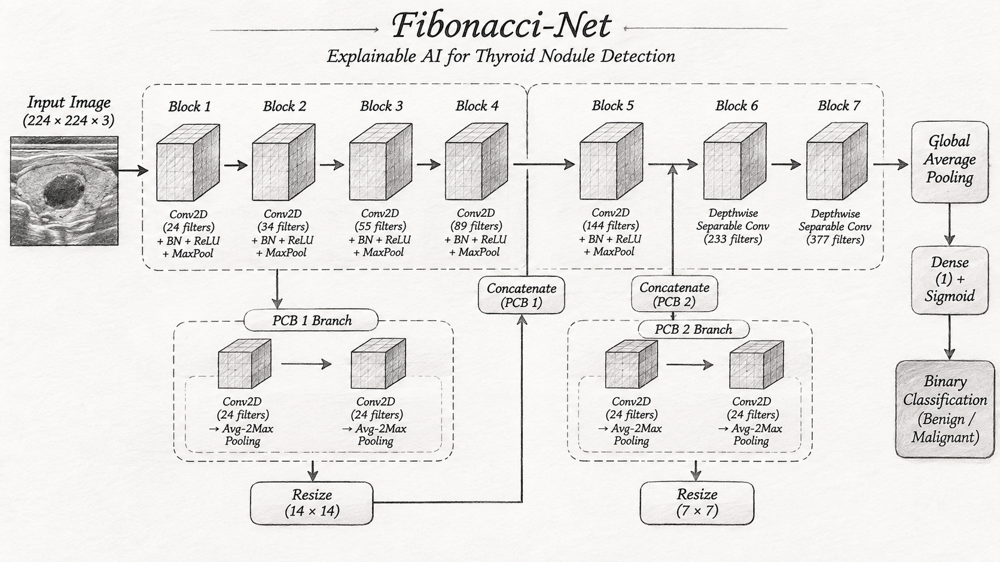

## **Import Libraries**

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout,
    BatchNormalization, Activation, GlobalAveragePooling2D,
    DepthwiseConv2D, Resizing, concatenate
)
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

from tensorflow.keras import layers
from tensorflow.keras.optimizers import Adam

import warnings
warnings.filterwarnings("ignore")

## **Dataset Path and Loading**

In [ ]:
# Path to the extracted dataset folder
DATASET_PATH = "../Thyroid Data"

# Check whether the folder exists
print(os.path.exists(DATASET_PATH))

# Display folders inside the dataset directory
print(os.listdir(DATASET_PATH))

True
['0', '1']


In [ ]:
# Define the class folders
categories = ['0', '1']

# Lists to store image paths and corresponding labels
image_paths = []
labels = []

# Collect images from each class folder
for category in categories:

    category_path = os.path.join(DATASET_PATH, category)

    # Check whether the class folder exists
    if not os.path.isdir(category_path):
        raise FileNotFoundError(f"Folder not found: {category_path}")

    for image_name in os.listdir(category_path):

        # Accept only supported image formats
        if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):

            image_path = os.path.join(category_path, image_name)

            image_paths.append(image_path)
            labels.append(int(category))

# Create a DataFrame containing image paths and labels
df = pd.DataFrame({
    'image_path': image_paths,
    'label': labels
})

print("\nTotal images:", len(df))
print("\nClass distribution:")
print(df['label'].value_counts())


Total images: 3115

Class distribution:
label
0    1905
1    1210
Name: count, dtype: int64


## **Dataset Exploration**

In [ ]:
# Check the number of rows and columns
df.shape

(3115, 2)

In [ ]:
# Display the column names
df.columns

Index(['image_path', 'label'], dtype='object')

In [ ]:
# Check duplicate records
df.duplicated().sum()

np.int64(0)

In [ ]:
# Check the class distribution
df['label'].value_counts()

,count
label,
0,1905
1,1210


## **Exploratory Data Analysis (EDA)**

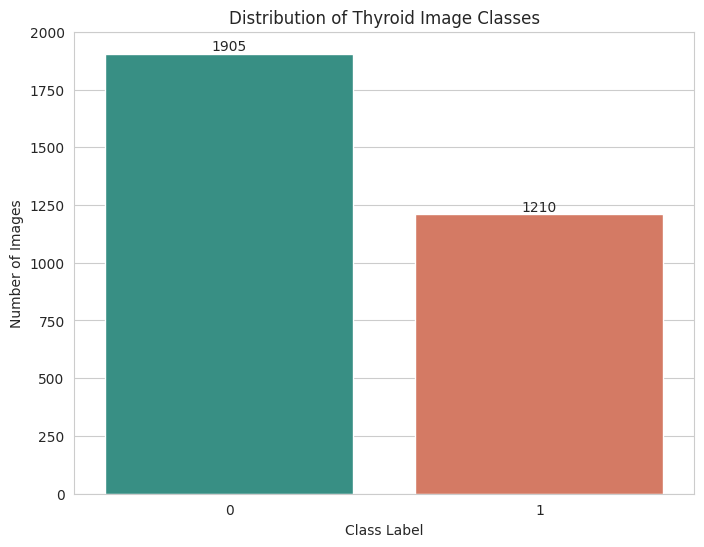

In [ ]:
# Set the visualization style
sns.set_style("whitegrid")

# Plot the number of images in each class
fig, ax = plt.subplots(figsize=(8, 6))

sns.countplot(data=df, x="label", palette=["#2A9D8F", "#E76F51"], ax=ax)

ax.set_title("Distribution of Thyroid Image Classes")
ax.set_xlabel("Class Label")
ax.set_ylabel("Number of Images")

# Display count above each bar
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom'
    )

plt.show()

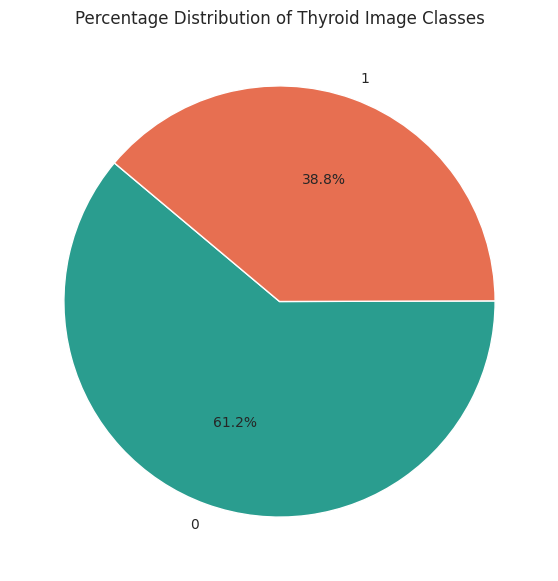

In [ ]:
# Calculate the number of images in each class
label_counts = df['label'].value_counts().sort_index()

# Plot the class proportions
plt.figure(figsize=(7, 7))

plt.pie(
    label_counts,
    labels=label_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=["#2A9D8F", "#E76F51"]
)

plt.title("Percentage Distribution of Thyroid Image Classes")
plt.show()

## **Sample Image Visualization**

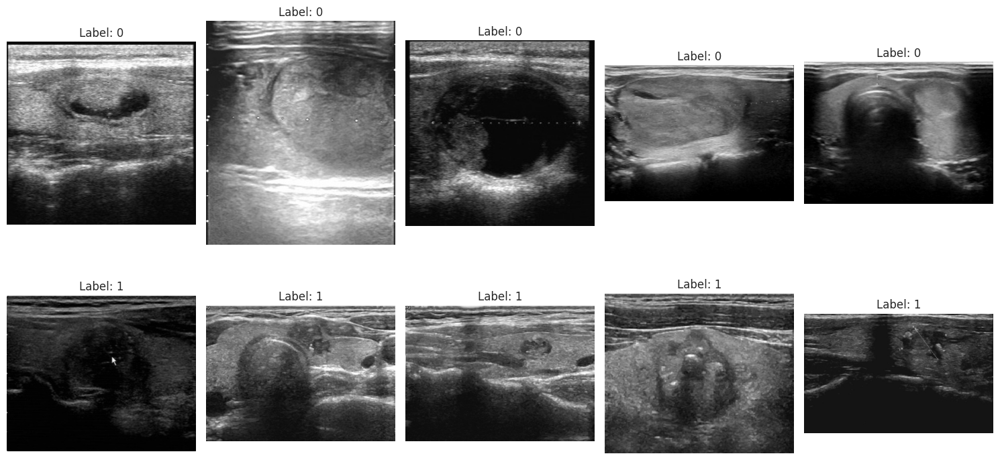

In [ ]:
# Select five images from each class
num_images = 5
categories = ['0', '1']

plt.figure(figsize=(15, 8))

for i, category in enumerate(categories):

    # Filter images belonging to the current class
    category_images = df[df['label'] == int(category)]['image_path'].iloc[:num_images]

    for j, img_path in enumerate(category_images):

        # Read the image
        img = cv2.imread(img_path)

        if img is not None:

            # Convert BGR to RGB for visualization
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            # Display the image
            plt.subplot(2, num_images, i * num_images + j + 1)
            plt.imshow(img)
            plt.axis('off')
            plt.title(f"Label: {category}")

        else:
            print("Unable to load:", img_path)

plt.tight_layout()
plt.show()

## **Data Augmentation-Class Balancing**

In [ ]:
# Step 1: Separate minority and majority class
majority_class = df[df['label'] == 0]
minority_class = df[df['label'] == 1]

# Step 2: Upsample the minority class
minority_upsampled = minority_class.sample(n=len(majority_class), replace=True, random_state=42)

# Step 3: Combine the two
df_resampled = pd.concat([majority_class, minority_upsampled]).sample(frac=1, random_state=42).reset_index(drop=True)

# Step 4: Encode labels if needed
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
df_resampled['category_encoded'] = label_encoder.fit_transform(df_resampled['label'])

# Show new class distribution
print("\n Class distribution after manual upsampling:")
print(df_resampled['category_encoded'].value_counts())


 Class distribution after manual upsampling:
category_encoded
0    1905
1    1905
Name: count, dtype: int64


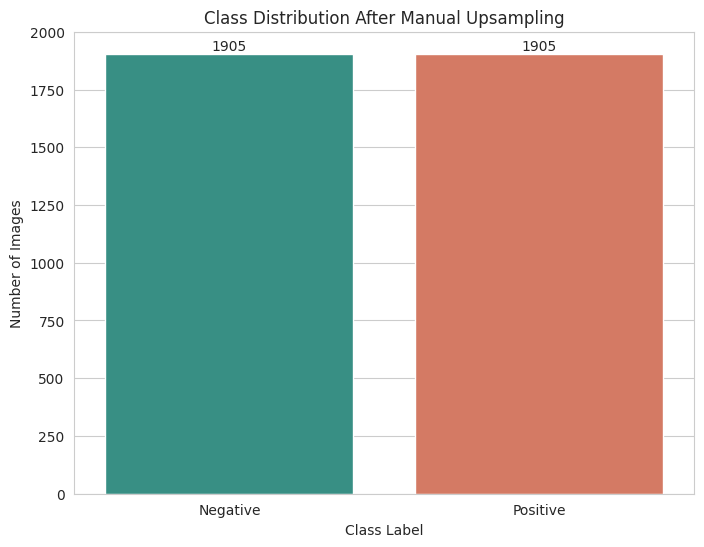

In [ ]:
# Set the visualization style
sns.set_style("whitegrid")

# Plot the number of images in each class
fig, ax = plt.subplots(figsize=(8, 6))

sns.countplot(data=df_resampled, x="category_encoded", palette=["#2A9D8F", "#E76F51"], ax=ax)

ax.set_title("Class Distribution After Manual Upsampling")
ax.set_xlabel("Class Label")
ax.set_ylabel("Number of Images")
ax.set_xticklabels(["Negative", "Positive"])

# Display count above each bar
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom'
    )

plt.show()

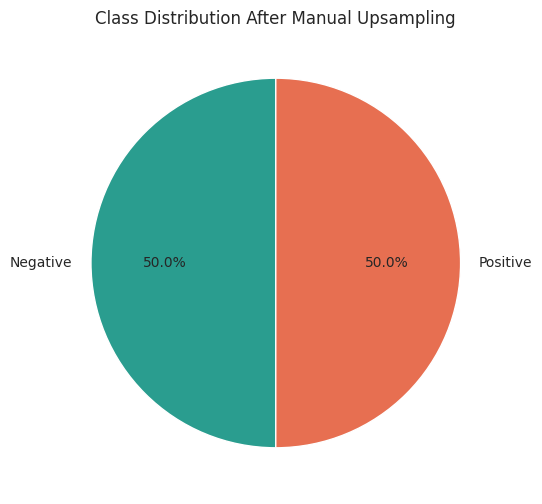

In [ ]:
# Set the visualization style
sns.set_style("whitegrid")

# Calculate class distribution
class_counts = df_resampled["category_encoded"].value_counts().sort_index()

# Plot the class distribution
fig, ax = plt.subplots(figsize=(8, 6))

ax.pie(
    class_counts.values,
    labels=["Negative", "Positive"],
    colors=["#2A9D8F", "#E76F51"],
    autopct='%1.1f%%',
    startangle=90
)

ax.set_title("Class Distribution After Manual Upsampling")

plt.show()

## **Configuration**

In [ ]:
df_resampled['category_encoded'] = df_resampled['category_encoded'].astype(str)

## **Dataset Splitting**

In [ ]:
train_df_new, temp_df_new = train_test_split(
    df_resampled,
    train_size=0.8,
    shuffle=True,
    random_state=42,
    stratify=df_resampled['category_encoded']
)

In [ ]:
valid_df_new, test_df_new = train_test_split(
    temp_df_new,
    test_size=0.5,
    shuffle=True,
    random_state=42,
    stratify=temp_df_new['category_encoded']
)

## **Image Preprocessing and Generators**

In [ ]:
batch_size = 16
img_size = (224, 224)
channels = 3
img_shape = (img_size[0], img_size[1], channels)

tr_gen = ImageDataGenerator(rescale=1./255)
ts_gen = ImageDataGenerator(rescale=1./255)

train_gen_new = tr_gen.flow_from_dataframe(
    train_df_new,
    x_col='image_path',
    y_col='category_encoded',
    target_size=img_size,
    class_mode='binary',
    color_mode='rgb',
    shuffle=True,
    batch_size=batch_size
)

valid_gen_new = ts_gen.flow_from_dataframe(
    valid_df_new,
    x_col='image_path',
    y_col='category_encoded',
    target_size=img_size,
    class_mode='binary',
    color_mode='rgb',
    shuffle=True,
    batch_size=batch_size
)

test_gen_new = ts_gen.flow_from_dataframe(
    test_df_new,
    x_col='image_path',
    y_col='category_encoded',
    target_size=img_size,
    class_mode='binary',
    color_mode='rgb',
    shuffle=False,
    batch_size=batch_size
)

Found 3048 validated image filenames belonging to 2 classes.
Found 381 validated image filenames belonging to 2 classes.
Found 381 validated image filenames belonging to 2 classes.


## **GPU Configuration**

In [ ]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [ ]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU is set for TensorFlow")
    except RuntimeError as e:
        print(e)

GPU is set for TensorFlow


## **Model Development – FibonacciNet**

**For skip connections**

In [ ]:
class Avg2MaxPooling(layers.Layer):
    """Novel Avg-2Max Pooling layer (as per paper)"""
    def __init__(self, pool_size=3, strides=2, padding='same'):
        super(Avg2MaxPooling, self).__init__()
        self.avg_pool = layers.AveragePooling2D(pool_size, strides, padding)
        self.max_pool = layers.MaxPooling2D(pool_size, strides, padding)

    def call(self, inputs):
        return self.avg_pool(inputs) - (self.max_pool(inputs) + self.max_pool(inputs))  # To explicitly emphasizes on edges

In [ ]:
class DepthwiseSeparableConv(layers.Layer):
    """Depthwise Separable Convolution with ReLU"""
    def __init__(self, filters, kernel_size=3, strides=1): # point wise
        super(DepthwiseSeparableConv, self).__init__()
        self.dw = layers.DepthwiseConv2D(kernel_size, strides, padding='same')
        self.pw = layers.Conv2D(filters, 1, strides=1)
        self.bn = layers.BatchNormalization()

    def call(self, inputs):
        x = self.dw(inputs)
        x = self.pw(x)
        return tf.nn.relu(self.bn(x))

def create_fibonacci_net(input_shape=(224, 224, 3), num_classes=1):
    inputs = layers.Input(shape=input_shape)

    # Block Architecture Starts

    # --- Block 1 (21 filters) ---
    x = layers.Conv2D(21, 3, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)  # 112x112

    # --- Block 2 (34 filters) ---
    x = layers.Conv2D(34, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x2 = layers.ReLU()(x)  # Save for pcb1 (56x56x34)
    x = layers.MaxPooling2D(2)(x)  # 56x56

    # --- Block 3 (55 filters) ---
    x = layers.Conv2D(55, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x3 = layers.ReLU()(x)  # Save for pcb2 (28x28x55)
    x = layers.MaxPooling2D(2)(x)  # 28x28

    # --- pcb1: Block 2 → Block 4 ---
    pcb1 = layers.Conv2D(24, 3, padding='same')(x2)  # 56x56x24
    pcb1 = Avg2MaxPooling()(pcb1)  # 28x28x24
    pcb1 = layers.Conv2D(24, 3, padding='same')(pcb1)  # Maintain 28x28x24
    pcb1 = Avg2MaxPooling()(pcb1)  # 14x14x24 (now matches Block 4)

    # --- Block 4 (89 filters) ---
    x = layers.Conv2D(89, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)  # 14x14x89

    # Resize pcb1 to match x
    pcb1 = layers.Resizing(14, 14)(pcb1)

    x = layers.concatenate([x, pcb1])  # 14x14x(89+24)

    # --- pcb2: Block 3 → Block 5 ---
    pcb2 = layers.Conv2D(24, 3, padding='same')(x3)  # 28x28x24
    pcb2 = Avg2MaxPooling()(pcb2)  # 14x14x24
    pcb2 = layers.Conv2D(24, 3, padding='same')(pcb2)  # Maintain 14x14x24
    pcb2 = Avg2MaxPooling()(pcb2)  # 7x7x24 (matches Block 5)

    # --- Block 5 (144 filters) ---
    x = layers.Conv2D(144, 3, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)  # 7x7x144

    # Resize pcb2 to match x
    pcb2 = layers.Resizing(7, 7)(pcb2)

    x = layers.concatenate([x, pcb2])  # 7x7x(144+24)

    # --- Block 6 (233 filters, DWSC) ---
    x = DepthwiseSeparableConv(233)(x)  # 7x7x233

    # --- Block 7 (377 filters, DWSC) ---
    x = DepthwiseSeparableConv(377)(x)  # 7x7x377

    # --- Output ---
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation='sigmoid')(x)

    return Model(inputs, outputs)

In [ ]:
model = create_fibonacci_net(num_classes=1)  # For 2-class nodule classification
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        588 │ input_layer[0][0] │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 224, 224,  │         84 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 224, 224,  │          0 │ batch_normalizat… │
│                     │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 21)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │      6,460 │ max_pooling2d[0]… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        136 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     16,885 │ max_pooling2d_1[… │
│                     │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        220 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 34)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      7,368 │ re_lu_1[0][0]     │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 28, 28,    │     44,144 │ max_pooling2d_2[… │
│                     │ 89)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ avg2_max_pooling    │ (None, 56, 56,    │          0 │ conv2d_3[0][0]    │
│ (Avg2MaxPooling)    │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        356 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 89)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │      5,208 │ avg2_max_pooling

 Total params: 380,152 (1.45 MB)

 Trainable params: 378,246 (1.44 MB)

 Non-trainable params: 1,906 (7.45 KB)

## **Model Compilation**

In [ ]:
# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC()]
)

In [ ]:
# Callbacks to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

In [ ]:
# Fit the model
history1 = model.fit(
    train_gen_new,
    validation_data=valid_gen_new,
    epochs=30,
    batch_size=32,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 523s 3s/step - accuracy: 0.6467 - auc: 0.7074 - loss: 0.6244 - val_accuracy: 0.4961 - val_auc: 0.5982 - val_loss: 0.6924 - learning_rate: 1.0000e-04
Epoch 2/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - accuracy: 0.7044 - auc: 0.7803 - loss: 0.5647 - val_accuracy: 0.6142 - val_auc: 0.6811 - val_loss: 0.6777 - learning_rate: 1.0000e-04
Epoch 3/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 18s 92ms/step - accuracy: 0.7428 - auc: 0.8192 - loss: 0.5260 - val_accuracy: 0.6693 - val_auc: 0.7827 - val_loss: 0.5994 - learning_rate: 1.0000e-04
Epoch 4/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 19s 97ms/step - accuracy: 0.7844 - auc: 0.8628 - loss: 0.4735 - val_accuracy: 0.6955 - val_auc: 0.8146 - val_loss: 0.5456 - learning_rate: 1.0000e-04
Epoch 5/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 18s 93ms/step - accuracy: 0.8205 - auc: 0.9066 - loss: 0.4048 - val_accuracy: 0.7323 - val_auc: 0.8750 - val_loss: 0.5519 - learning_rate: 1.0000e-04
Epoch 6/30
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/st

## **Training Performance Visualization**

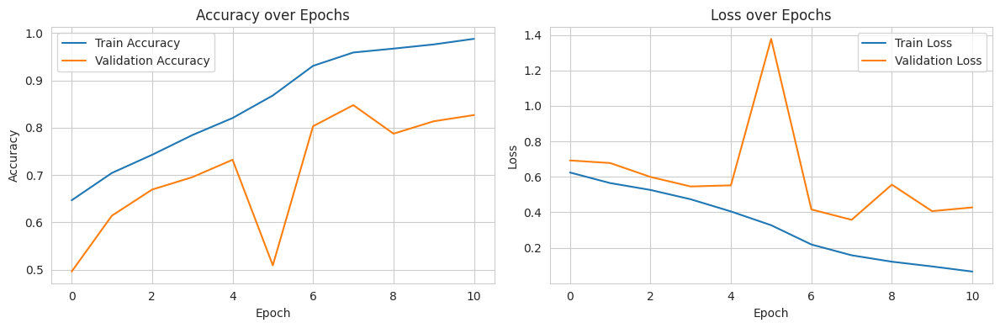

In [ ]:
def plot_history(history1):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history1.history['accuracy'], label='Train Accuracy')
    plt.plot(history1.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history1.history['loss'], label='Train Loss')
    plt.plot(history1.history['val_loss'], label='Validation Loss')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history1)

## **Model Evaluation**

In [ ]:
test_gen_new.reset()
y_true = test_gen_new.classes
y_pred_probs = model.predict(test_gen_new, steps=len(test_gen_new))
y_pred = (y_pred_probs > 0.5).astype(int)

24/24 ━━━━━━━━━━━━━━━━━━━━ 50s 2s/step


## **Confusion Matrix**

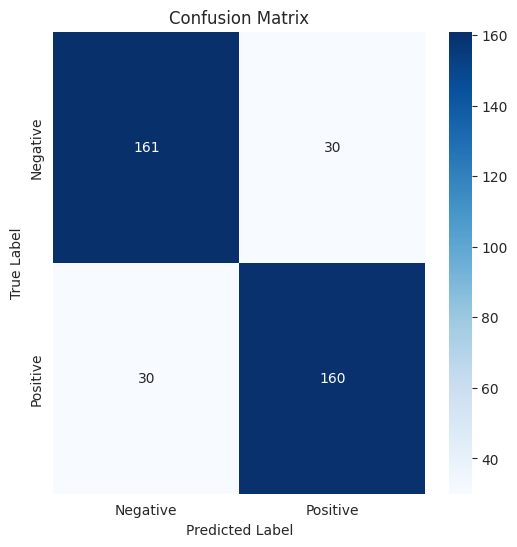

In [ ]:
def plot_confusion_matrix(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

plot_confusion_matrix(y_true, y_pred)

## **Classification Report and ROC Curve and AUC**


Classification Report:
              precision    recall  f1-score   support

    Negative       0.84      0.84      0.84       191
    Positive       0.84      0.84      0.84       190

    accuracy                           0.84       381
   macro avg       0.84      0.84      0.84       381
weighted avg       0.84      0.84      0.84       381



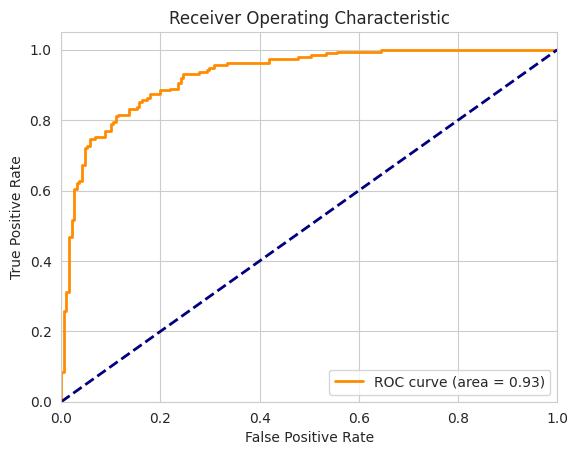

In [ ]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Negative', 'Positive']))

fpr, tpr, thresholds = roc_curve(y_true, y_pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

## **Model Saving**

In [ ]:
# Save the full model (architecture + weights + optimizer)
# Save the trained model
model.save("../models/Thyroid_cancer_model.keras")
print("Model saved successfully!")

Model saved successfully!


## **Explainability Using Grad-CAM**

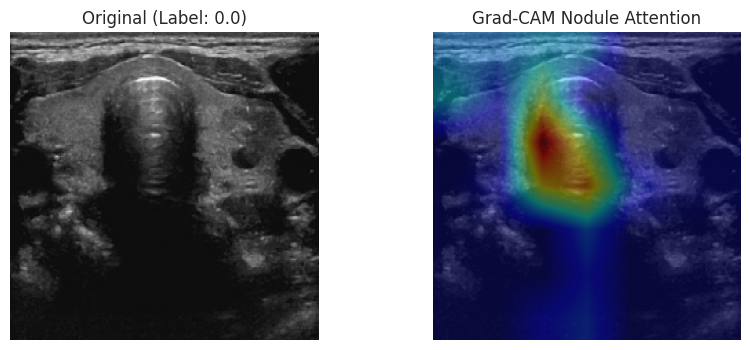

In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # First, we create a model that maps the input image to the activations
    # of the last conv layer as well as the output predictions
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Then, we compute the gradient of the top predicted class for our input image
    # with respect to the activations of the last conv layer
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            # For binary classification with sigmoid, we look at the single output value
            class_channel = preds[:, 0]
        else:
            class_channel = preds[:, pred_index]

    # This is the gradient of the output node with regard to the output feature map of the last conv layer
    grads = tape.gradient(class_channel, last_conv_layer_output)

    # This is a vector where each entry is the mean intensity of the gradient over a specific feature map channel
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # We multiply each channel in the feature map array by "how important this channel is" with regard to the top predicted class
    # then sum all the channels to obtain the heatmap class activation
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # For visualization purpose, we will also normalize the heatmap between 0 & 1
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Select a sample from the test generator
# ImageDataGenerator returns (x, y) batches
test_gen_new.reset()
sample_batch_x, sample_batch_y = next(test_gen_new)
img_sample = sample_batch_x[0:1] # Take first image of batch
label_sample = sample_batch_y[0]

# Find the last layer of the DWSC tail
# Your FibonacciNet uses DepthwiseSeparableConv layers
last_conv_name = None
for layer in reversed(model.layers):
    if isinstance(layer, DepthwiseSeparableConv) or "depthwise_separable_conv" in layer.name:
        last_conv_name = layer.name
        break

if last_conv_name:
    heatmap = make_gradcam_heatmap(img_sample, model, last_conv_name)

    # Display result
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(img_sample[0])
    plt.title(f"Original (Label: {label_sample})")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_sample[0])
    # Resize heatmap to match image size
    resized_heatmap = cv2.resize(heatmap, (img_size[0], img_size[1]))
    plt.imshow(resized_heatmap, alpha=0.4, cmap='jet')
    plt.title("Grad-CAM Nodule Attention")
    plt.axis('off')
    plt.show()
else:
    print("Could not find a valid convolutional layer for Grad-CAM.")

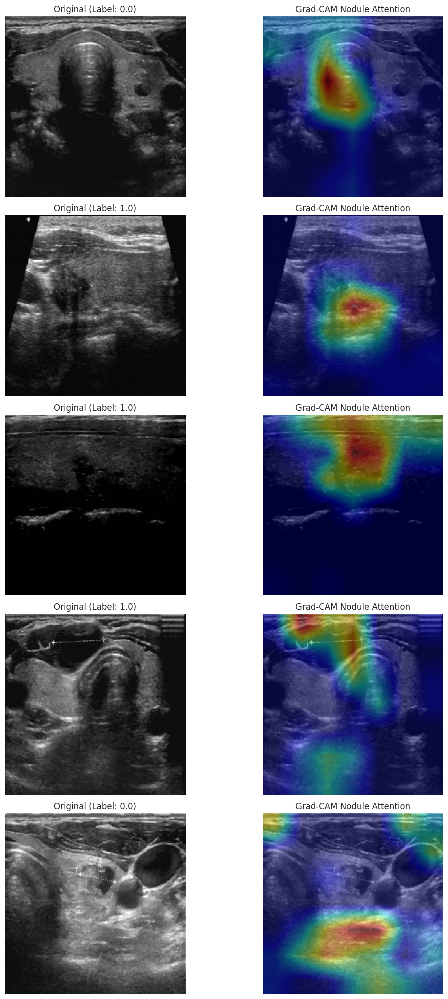

In [ ]:
# Select 5 images from the test generator
test_gen_new.reset()
sample_batch_x, sample_batch_y = next(test_gen_new)

# Take the first 5 images
img_samples = sample_batch_x[:5]
label_samples = sample_batch_y[:5]

# Find the last layer of the DWSC tail
last_conv_name = None

for layer in reversed(model.layers):
    if isinstance(layer, DepthwiseSeparableConv) or "depthwise_separable_conv" in layer.name:
        last_conv_name = layer.name
        break

if last_conv_name:

    # Display Grad-CAM for 5 images
    fig, axes = plt.subplots(5, 2, figsize=(12, 20))

    for i in range(5):

        img_sample = img_samples[i:i+1]

        # Generate heatmap
        heatmap = make_gradcam_heatmap(
            img_sample, model, last_conv_name
        )

        # Original image
        axes[i, 0].imshow(img_sample[0])
        axes[i, 0].set_title(f"Original (Label: {label_samples[i]})")
        axes[i, 0].axis('off')

        # Grad-CAM overlay
        axes[i, 1].imshow(img_sample[0])

        resized_heatmap = cv2.resize(
            heatmap, (img_size[0], img_size[1])
        )

        axes[i, 1].imshow(resized_heatmap, alpha=0.4, cmap='jet')
        axes[i, 1].set_title("Grad-CAM Nodule Attention")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("Could not find a valid convolutional layer for Grad-CAM.")